# Actividad Intervalos de confianza

## Alumno: Edilberto Antonio Gómez García

### 1

In [78]:
import pandas as pd
import numpy as np

datos = pd.read_csv('conjunto_de_datos_concentradohogar_enigh2024_ns.csv')
datos.columns

Index(['folioviv', 'foliohog', 'ubica_geo', 'tam_loc', 'est_socio', 'est_dis',
       'upm', 'factor', 'clase_hog', 'sexo_jefe',
       ...
       'mater_serv', 'material', 'servicio', 'deposito', 'prest_terc',
       'pago_tarje', 'deudas', 'balance', 'otras_erog', 'smg'],
      dtype='object', length=126)

In [79]:
datos.shape

(91414, 126)

In [80]:
datos = datos[['ing_cor', 'ubica_geo', 'factor', 'est_dis', 'upm']]
datos.head()

,ing_cor,ubica_geo,factor,est_dis,upm
0,138232.38,1001,207,1,1
1,118014.04,1001,207,1,1
2,46866.32,1001,207,1,1
3,110430.10,1001,207,1,1
4,99494.12,1001,196,2,2


In [81]:
datos.dtypes

,0
ing_cor,float64
ubica_geo,int64
factor,int64
est_dis,int64
upm,int64


In [82]:
datos.isna().sum()

,0
ing_cor,0
ubica_geo,0
factor,0
est_dis,0
upm,0


In [83]:
datos['ubica_geo'] = datos['ubica_geo'].astype('str')
datos['ubica_geo'] = datos['ubica_geo'].str[:2]
datos['ubica_geo']

,ubica_geo
0,10
1,10
2,10
3,10
4,10
...,...
91409,32
91410,32
91411,32
91412,32


In [84]:
datos_puebla = datos[datos['ubica_geo'] == '21']
datos_nl = datos[datos['ubica_geo'] == '19']
print(datos_puebla.shape)
print(datos_nl.shape)

(2198, 5)
(3796, 5)


In [85]:
muestra_puebla = len(datos_puebla)
muestra_nl = len(datos_nl)

media_puebla = datos_puebla['ing_cor'].mean()
media_nl = datos_nl['ing_cor'].mean()

desviacion_puebla = datos_puebla['ing_cor'].std(ddof=1)
desviacion_nl = datos_nl['ing_cor'].std(ddof=1)

mediana_puebla = datos_puebla['ing_cor'].median()
mediana_nl = datos_nl['ing_cor'].median()

cuartiles_puebla = datos_puebla['ing_cor'].quantile([0.25, 0.75])
cuartiles_nl = datos_nl['ing_cor'].quantile([0.25, 0.75])

print(f'Datos puebla: \nMuestra: {muestra_puebla} \nMedia: {media_puebla} \nDesviacion: {desviacion_puebla} \nMediana: {mediana_puebla} \nCuartiles: {cuartiles_puebla}')
print(f'\nDatos NL: \nMuestra: {muestra_nl} \nMedia: {media_nl} \nDesviacion: {desviacion_nl} \nMediana: {mediana_nl} \nCuartiles: {cuartiles_nl}')

Datos puebla: 
Muestra: 2198 
Media: 61341.043689717924 
Desviacion: 50557.29140251398 
Mediana: 47095.485 
Cuartiles: 0.25    30419.9500
0.75    75333.2075
Name: ing_cor, dtype: float64

Datos NL: 
Muestra: 3796 
Media: 90808.35069810327 
Desviacion: 304168.9803512327 
Mediana: 63817.115000000005 
Cuartiles: 0.25     38722.3475
0.75    101777.4425
Name: ing_cor, dtype: float64


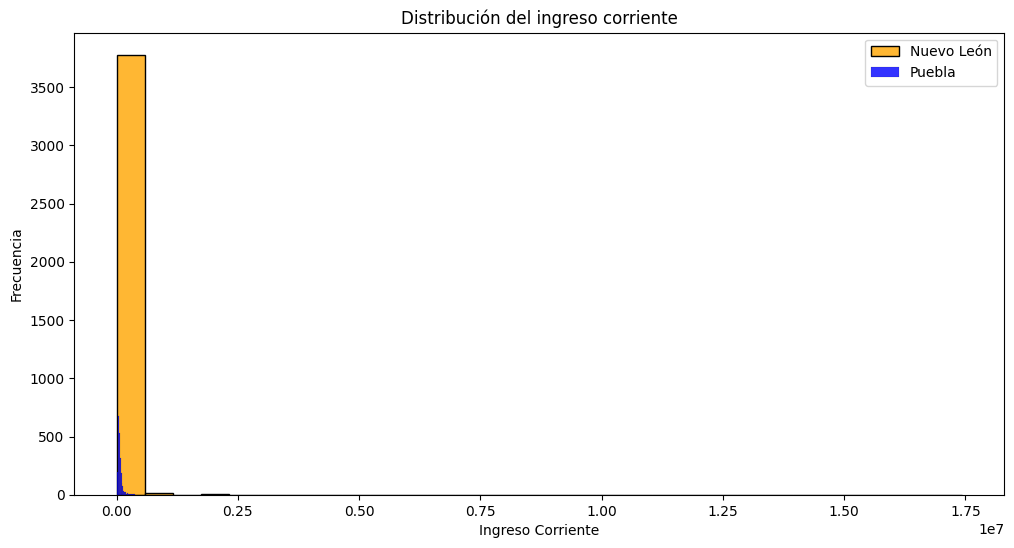

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.histplot(datos_nl['ing_cor'], color='orange', label='Nuevo León', alpha=0.8, bins=30)

sns.histplot(datos_puebla['ing_cor'], color='blue', label='Puebla', alpha=0.8, bins=30)

plt.title('Distribución del ingreso corriente')
plt.xlabel('Ingreso Corriente')
plt.ylabel('Frecuencia')
plt.legend()

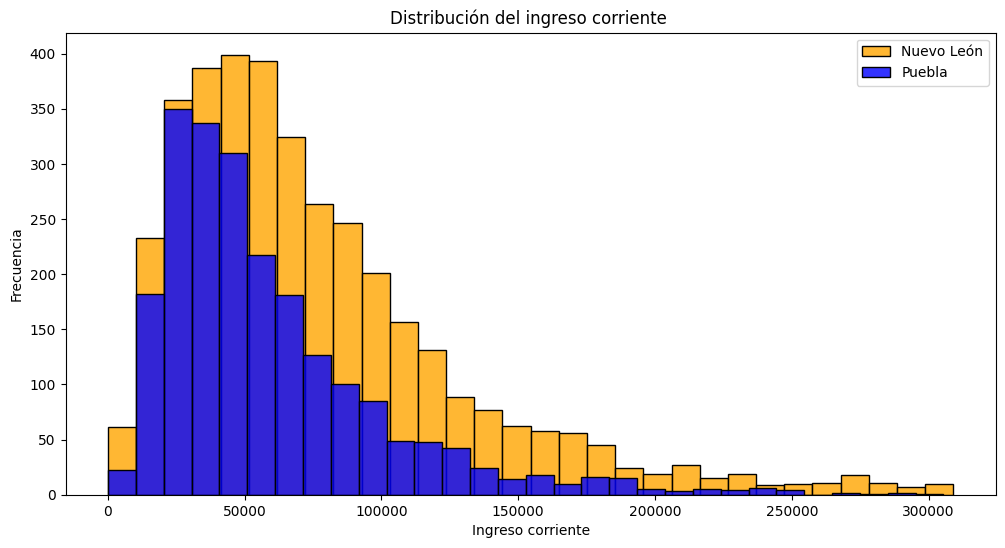

In [87]:
limite = datos['ing_cor'].quantile(0.99) # esto porque notamos un sesgo bastante alto hacia la derecha

plt.figure(figsize=(12, 6))

sns.histplot(datos_nl[datos_nl['ing_cor'] <= limite]['ing_cor'], color='orange', label='Nuevo León', alpha=0.8, bins=30)

sns.histplot(datos_puebla[datos_puebla['ing_cor'] <= limite]['ing_cor'], color='blue', label='Puebla', alpha=0.8, bins=30)

plt.title('Distribución del ingreso corriente ')
plt.xlabel('Ingreso corriente')
plt.ylabel('Frecuencia')
plt.legend()

/tmp/ipykernel_547/88190678.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Text(0.5, 0, 'Estado')

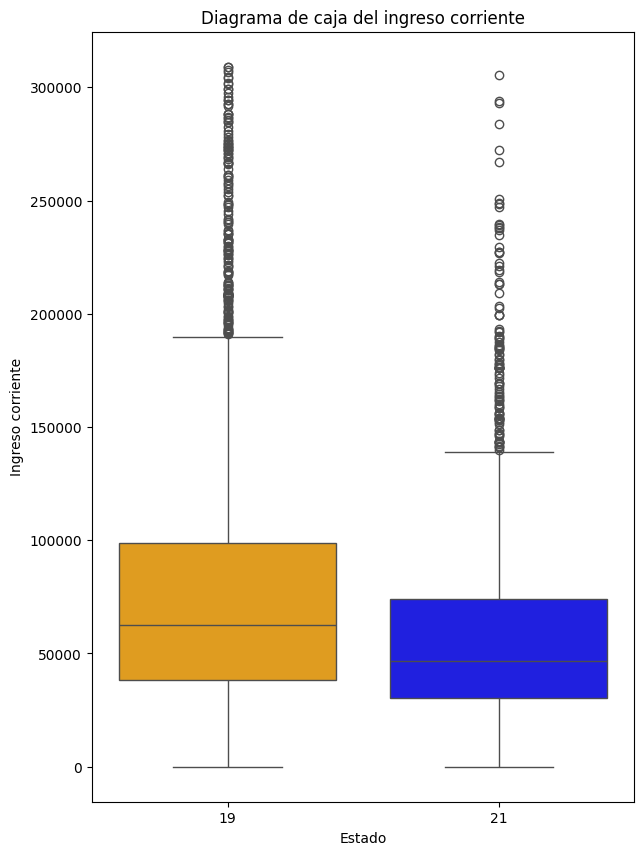

In [88]:
datos_comparativa = datos[datos['ubica_geo'].isin(['21', '19'])].copy()

datos_graficar = datos_comparativa[datos_comparativa['ing_cor'] <= limite]

plt.figure(figsize=(7, 10))

sns.boxplot(
    data=datos_graficar,
    x='ubica_geo',
    y='ing_cor',
    palette={'21': 'blue', '19': 'orange'}
)

plt.title('Diagrama de caja del ingreso corriente')
plt.ylabel('Ingreso corriente')
plt.xlabel('Estado')

Por el primer gráfico de hsitograma, notamos rápidamente el sesgo tan fuerte que tiene positivamente, por lo que esto nos indica presencia de valores atípicos extremos, es decir, hogares con ingresos bastantes altos, lo que nos genera una asimetria.

La media y mediana como ya vimos en el calculo de ella difieren bastante precisamente por la existencia de estos valores tan altos.

### 2

In [89]:
error_estandar_puebla = desviacion_puebla / np.sqrt(muestra_puebla)

import scipy.stats as stats

def intervalo_t(alpha, n, media_muestral, desviacion_muestral):
    nivel_probabilidad = 1 - (alpha/2)
    grados_libertad = n - 1

    a = stats.t.ppf(nivel_probabilidad, df=grados_libertad)

    limite_inf = media_muestral - a * (desviacion_muestral / np.sqrt(n))
    limite_sup = media_muestral + a * (desviacion_muestral / np.sqrt(n))

    return limite_inf, limite_sup

alpha = 0.05

lim_inf, lim_sup = intervalo_t(alpha=alpha, n=muestra_puebla, media_muestral=media_puebla, desviacion_muestral=desviacion_puebla)
print(f'El intervalo de confianza para la poblacion puebla es: ({lim_inf}, {lim_sup})')


El intervalo de confianza para la poblacion puebla es: (59226.30179289666, 63455.78558653919)


Con un 95% de confianza se puede afirmar que el verdadero ingreso promedio poblacional de Puebla se encuentra dentro del intervalo (59,226.30 y 63,455.78)

El intervalo significa que si se extraen 100 muestras del mismo tamaño y se construyen 100 intervalos de confianza esperariamos que 95 de estos 100 intervalos logren capturar la verdadero ingreso promedio.

### 3

In [90]:
diferencia_medias = media_nl - media_puebla

error_estandar =  np.sqrt((desviacion_nl**2/muestra_nl)+(desviacion_puebla**2/muestra_puebla))
error_estandar

nu = (error_estandar**4)/((desviacion_nl**2/muestra_nl)**2/(muestra_nl-1)+(desviacion_puebla**2/muestra_puebla)**2/(muestra_puebla-1))
nu

valor_critico = stats.t.ppf(0.975, df=nu)
valor_critico

limite_inf_w = diferencia_medias - valor_critico * error_estandar
limite_sup_w = diferencia_medias + valor_critico * error_estandar
print(f'El intervalo de confianza para la diferencia de medias es: ({limite_inf_w}, {limite_sup_w})')

El intervalo de confianza para la diferencia de medias es: (19560.179215252396, 39374.43480151829)


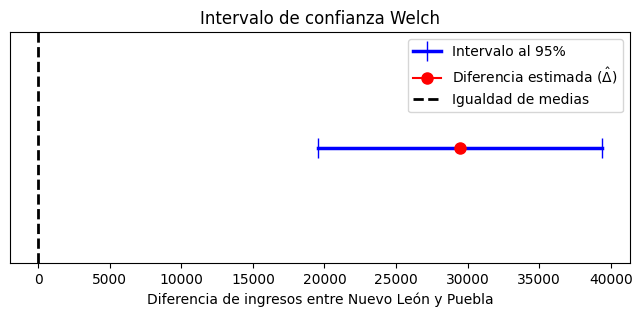

In [91]:
plt.figure(figsize=(8, 3))

plt.plot([limite_inf_w, limite_sup_w], [1, 1], color='blue', marker='|', markersize=15, lw=2.5, label='Intervalo al 95%')

plt.plot(diferencia_medias, 1, color='red', marker='o', markersize=8, label=r'Diferencia estimada ($\hat{\Delta}$)')

plt.axvline(x=0, color='black', linestyle='--', lw=2, label='Igualdad de medias')

plt.yticks([])
plt.xlabel('Diferencia de ingresos entre Nuevo León y Puebla')
plt.title('Intervalo de confianza Welch')
plt.legend()

No contiene al cero el intervalo, debido a que si existe una diferencia entre las medias de ingreso entre Puebla y Nuevo León.

Esto nos permite concluir que estadisiticamente si hay un diferencia significativa entre los ingresos promedio entre los estados de Puebla y Nuevo Leon con un 95% de confianza y como fue la diferencia de Nuevo León menos Puebla, y el intervalo que obtuvimos fue con valores positivos, se llega a concluir que el promedio de ingresos entre Nuevo Leon es significativamente mayor a la de Puebla.

Y no hay causalidad, ya que esto no significa que si hay migración de Puebla a Nuevo León signifique que tenga un aumento en el ingreso, ya que sólo es una observación y no un experimento controlado.

### 4

In [92]:
def calcular_estadistico(x):

    estadistico=np.mean(x)

    return(estadistico)

def bootstraping(x, fun_estadistico, n_iteraciones):
    n=len(x)
    dist_boot=np.full(shape=n_iteraciones, fill_value=np.nan)

    for i in range(n_iteraciones):
        resample=np.random.choice(x, size=n, replace=True)
        dist_boot[i]=fun_estadistico(resample)

    return dist_boot

media_boot=bootstraping(x=datos_puebla['ing_cor'], fun_estadistico=calcular_estadistico, n_iteraciones=5000)

media_remuestreo = media_boot.mean()


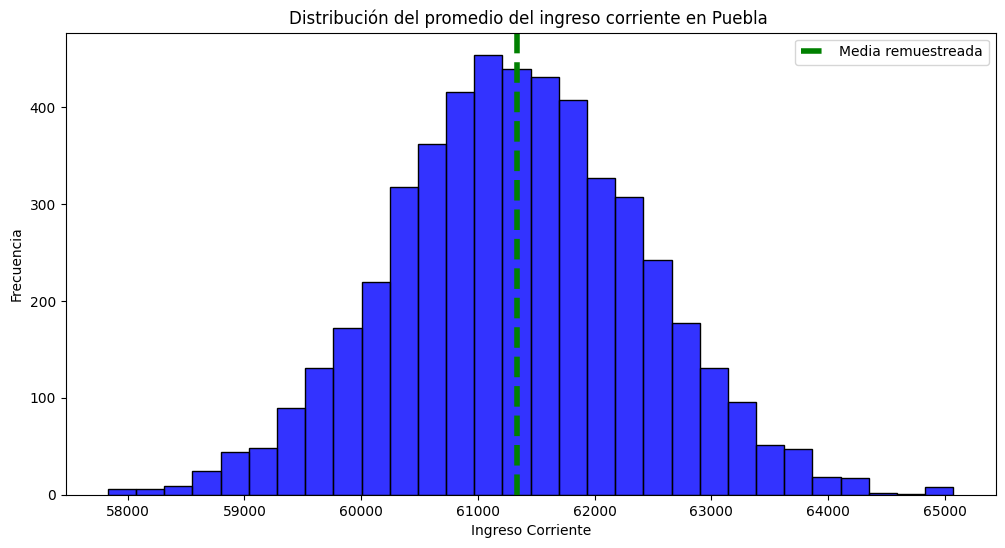

In [93]:
plt.figure(figsize=(12, 6))

sns.histplot(media_boot, color='blue', alpha=0.8, bins=30)
plt.axvline(x=media_remuestreo, color='green', linestyle='--', lw=4, label='Media remuestreada')

plt.title('Distribución del promedio del ingreso corriente en Puebla ')
plt.xlabel('Ingreso Corriente')
plt.ylabel('Frecuencia')
plt.legend()

In [94]:
lim_inf_b, lim_sup_b =  np.quantile(a=media_boot, q=[0.025, 0.975])

print(f'Recordemos que el intervalo de confianza en la parte dos fue {lim_inf} y {lim_sup}')
print(f'Mientras que para bootstraping es {lim_inf_b} y {lim_sup_b}')
print(f'Amplitud del primer intervalo {lim_sup - lim_inf}')
print(f'Amplitud del segundo intervalo {lim_sup_b - lim_inf_b}')

Recordemos que el intervalo de confianza en la parte dos fue 59226.30179289666 y 63455.78558653919
Mientras que para bootstraping es 59197.4677700182 y 63476.86455345769
Amplitud del primer intervalo 4229.483793642532
Amplitud del segundo intervalo 4279.396783439493


Notamos que si, son bastante similares sus valores tanto para sus limites inferiores como sus limites superiores, además sus amplitudes de igual manera son bastante similares teniendo una diferencia de aproximadamente de 50.

Una de las diferencias es que para el primer intervalo se uso la distribución t, la cuál es simetrica, por lo tanto se asumió que nuestra distribución es igual simetrica, pero ya sabemos que no es así, debido al alto sesgo positivo que tenemos, pero para el segundo intervalo se uso bootstraping, que es un método no parametrico, aquí no se asume ninguna distribución, por lo que para nuestros datos este podría ser una mejor forma de cosntruir el intervalo.